# TA-03: Prediksi Risiko Karyawan Resign (Employee Attrition) dengan Regresi Logistik

**Mata Kuliah:** Pembelajaran Mesin | **Dataset:** IBM HR Analytics Employee Attrition & Performance (Kaggle)

**Peran:** Data Scientist di bagian HR Analytics. Tim HR ingin mendeteksi lebih awal karyawan yang berisiko resign
agar bisa diberi tindakan retensi (diskusi karier, penyesuaian beban kerja, kompensasi) sebelum mereka pergi.

**Target:** `Attrition` (1 = resign, 0 = bertahan).

Alur notebook: muat data, EDA, preprocessing, split + scaling + SMOTE, latih model, evaluasi, interpretasi, simpan model (Joblib).

## 1. Import Library

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report,
                             confusion_matrix, precision_recall_fscore_support,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Memuat Data

Unduh dataset dari Kaggle (kata kunci: *IBM HR Analytics Employee Attrition*), lalu simpan di
`data/WA_Fn-UseC_-HR-Employee-Attrition.csv`.

In [2]:
DATA_PATH = Path("data/WA_Fn-UseC_-HR-Employee-Attrition.csv")
df = pd.read_csv(DATA_PATH)
print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

## 3. Eksplorasi Data (EDA)

### 3.1 Kualitas data
Cek nilai hilang, duplikat, dan kolom konstan atau kolom ID (tidak informatif untuk model).

In [4]:
print("Total nilai hilang :", int(df.isnull().sum().sum()))
print("Baris duplikat     :", int(df.duplicated().sum()))

konstan = [c for c in df.columns if df[c].nunique() == 1]
print("Kolom konstan      :", konstan)
print("Kolom ID           : ['EmployeeNumber']")

Total nilai hilang : 0
Baris duplikat     : 0
Kolom konstan      : ['EmployeeCount', 'Over18', 'StandardHours']
Kolom ID           : ['EmployeeNumber']


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


### 3.2 Distribusi target dan ketidakseimbangan kelas
Karyawan yang resign biasanya jauh lebih sedikit daripada yang bertahan. Jika dibiarkan, model cenderung "malas"
menebak semua karyawan bertahan dan tetap terlihat akurat.

           jumlah  persen (%)
Attrition                    
No           1233        83.9
Yes           237        16.1


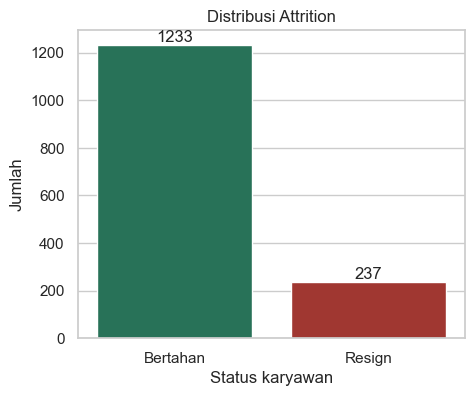

In [6]:
hitung = df["Attrition"].value_counts()
persen = df["Attrition"].value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({"jumlah": hitung, "persen (%)": persen}))

plt.figure(figsize=(5, 4))
ax = sns.countplot(x="Attrition", data=df, order=["No", "Yes"], palette=["#1B7F5C", "#B3261E"])
ax.set_xticklabels(["Bertahan", "Resign"])
ax.set_title("Distribusi Attrition")
ax.set_xlabel("Status karyawan")
ax.set_ylabel("Jumlah")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.show()

### 3.3 Hubungan fitur kategorikal dengan resign
Grafik menunjukkan persentase karyawan yang resign pada tiap kategori.

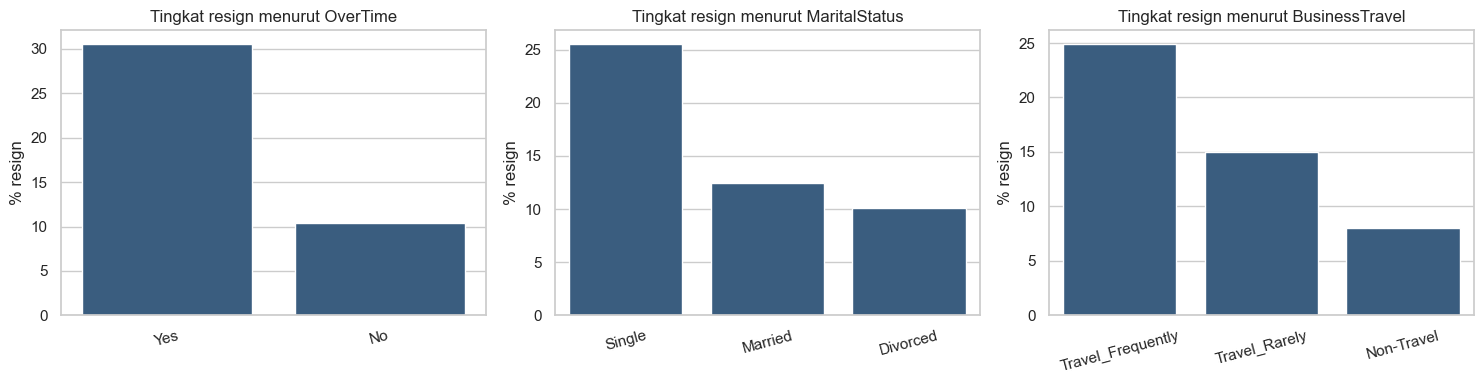

In [7]:
NUMERIC_COLS = [
    "Age", "MonthlyIncome", "DistanceFromHome", "TotalWorkingYears",
    "YearsAtCompany", "YearsSinceLastPromotion", "NumCompaniesWorked",
    "JobLevel", "StockOptionLevel",
    "JobSatisfaction", "EnvironmentSatisfaction", "WorkLifeBalance",
]
CATEGORICAL_COLS = ["OverTime", "MaritalStatus", "BusinessTravel"]

df["Resign"] = (df["Attrition"] == "Yes").astype(int)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, CATEGORICAL_COLS):
    rate = df.groupby(col)["Resign"].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color="#2F5D8A")
    ax.set_title(f"Tingkat resign menurut {col}")
    ax.set_ylabel("% resign")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

### 3.4 Hubungan fitur numerik dengan resign

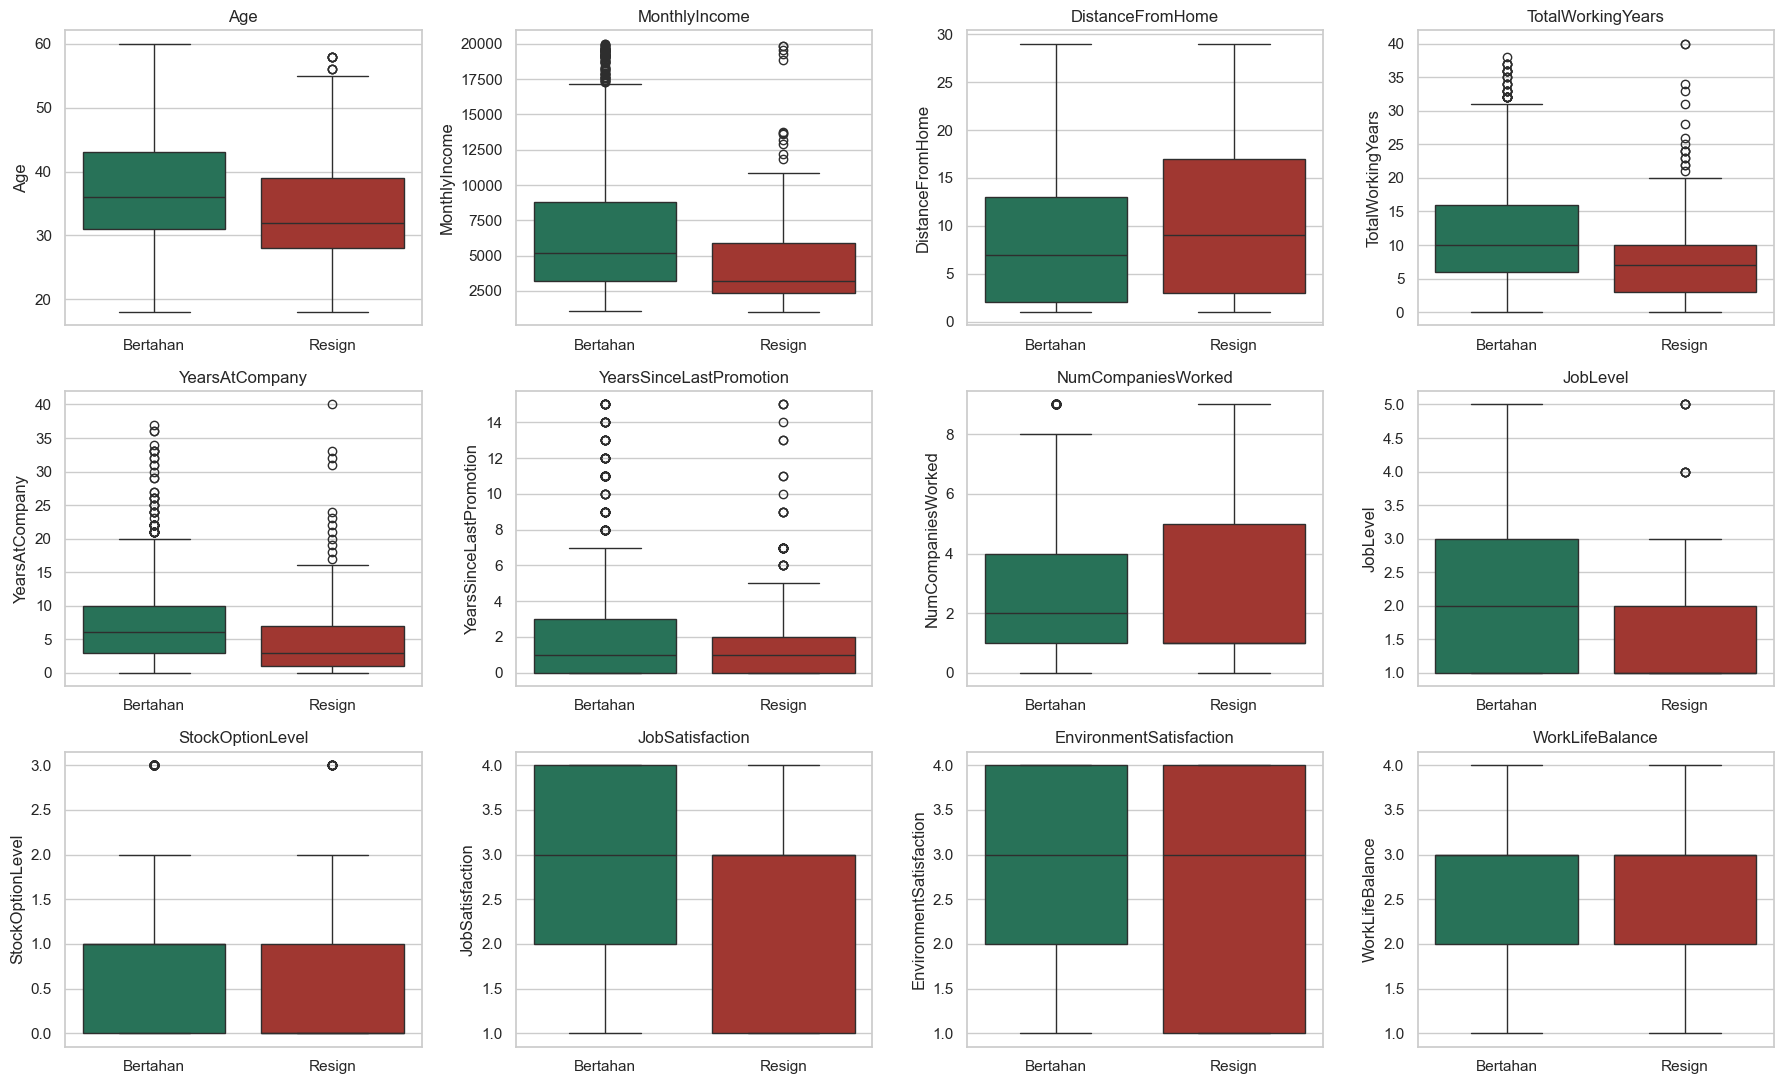

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for ax, col in zip(axes.ravel(), NUMERIC_COLS):
    sns.boxplot(x="Attrition", y=col, data=df, order=["No", "Yes"],
                palette=["#1B7F5C", "#B3261E"], ax=ax)
    ax.set_xticklabels(["Bertahan", "Resign"])
    ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout()
plt.show()

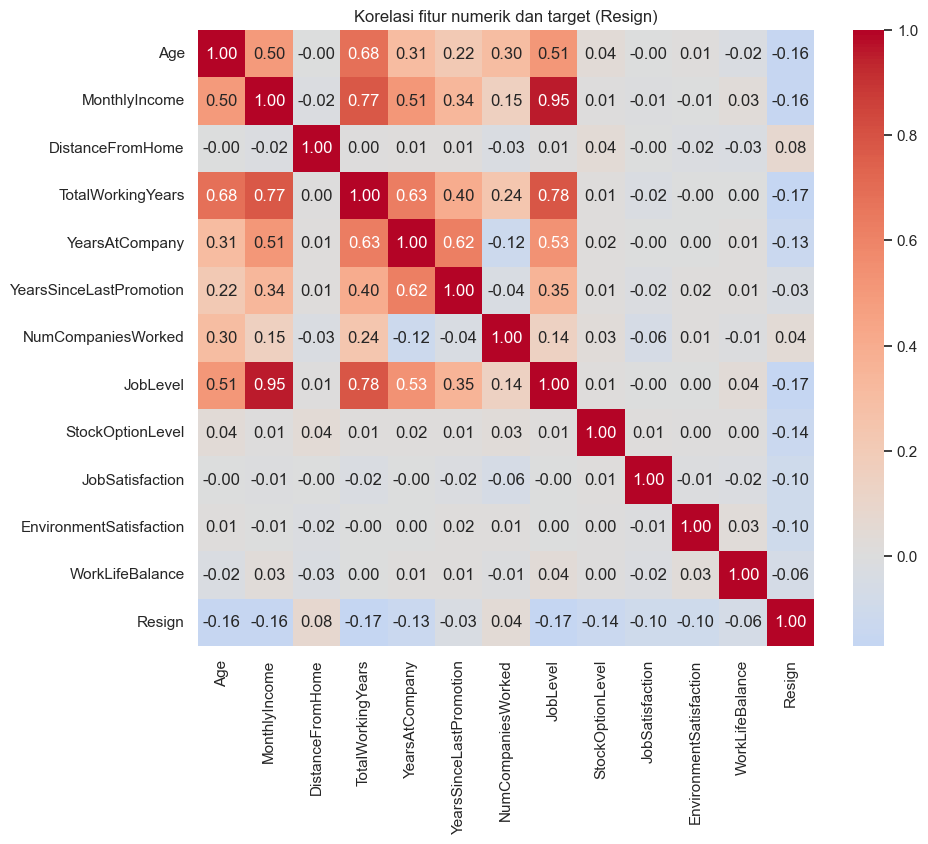

TotalWorkingYears         -0.171063
JobLevel                  -0.169105
MonthlyIncome             -0.159840
Age                       -0.159205
StockOptionLevel          -0.137145
YearsAtCompany            -0.134392
JobSatisfaction           -0.103481
EnvironmentSatisfaction   -0.103369
WorkLifeBalance           -0.063939
YearsSinceLastPromotion   -0.033019
NumCompaniesWorked         0.043494
DistanceFromHome           0.077924
Name: Resign, dtype: float64

In [9]:
plt.figure(figsize=(10, 8))
corr = df[NUMERIC_COLS + ["Resign"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Korelasi fitur numerik dan target (Resign)")
plt.show()

corr["Resign"].drop("Resign").sort_values()

**Catatan EDA (isi setelah melihat grafik di atas dengan data aslimu):** tuliskan 3-4 temuan utama, misalnya
kelompok mana yang tingkat resign-nya paling tinggi, dan fitur numerik mana yang paling berbeda antara yang resign
dan yang bertahan.

## 4. Preprocessing

- Buang kolom konstan (`EmployeeCount`, `Over18`, `StandardHours`) dan kolom ID (`EmployeeNumber`).
- Pilih fitur yang relevan, supaya formulir di aplikasi web tetap ringkas.
- Ubah target menjadi 0/1.
- Ubah variabel kategorikal menjadi numerik dengan *one-hot encoding*.

In [10]:
FEATURES = NUMERIC_COLS + CATEGORICAL_COLS

X = pd.get_dummies(df[FEATURES], columns=CATEGORICAL_COLS, dtype=int)
y = df["Resign"]

print("Jumlah fitur setelah encoding:", X.shape[1])
X.head()

Jumlah fitur setelah encoding: 20


,Age,MonthlyIncome,DistanceFromHome,TotalWorkingYears,YearsAtCompany,YearsSinceLastPromotion,NumCompaniesWorked,JobLevel,StockOptionLevel,JobSatisfaction,EnvironmentSatisfaction,WorkLifeBalance,OverTime_No,OverTime_Yes,MaritalStatus_Divorced,MaritalStatus_Married,MaritalStatus_Single,BusinessTravel_Non-Travel,BusinessTravel_Travel_Frequently,BusinessTravel_Travel_Rarely
0,41,5993,1,8,6,0,8,2,0,4,2,1,0,1,0,0,1,0,0,1
1,49,5130,8,10,10,1,1,2,1,2,3,3,1,0,0,1,0,0,1,0
2,37,2090,2,7,0,0,6,1,0,3,4,3,0,1,0,0,1,0,0,1
3,33,2909,3,8,8,3,1,1,0,3,4,3,0,1,0,1,0,0,1,0
4,27,3468,2,6,2,2,9,1,1,2,1,3,1,0,0,1,0,0,0,1


## 5. Split Data, Scaling, dan SMOTE

Urutan yang benar, agar tidak terjadi *data leakage*:

1. **Split** dulu (stratified, supaya proporsi resign sama di train dan test).
2. **Scaling**: `StandardScaler` di-*fit* hanya pada data latih, lalu dipakai untuk men-transform data uji.
3. **SMOTE** hanya pada data latih. Data uji tidak boleh disentuh.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporsi resign train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[NUMERIC_COLS] = scaler.fit_transform(X_train[NUMERIC_COLS])
X_test_s[NUMERIC_COLS] = scaler.transform(X_test[NUMERIC_COLS])

smote = SMOTE(random_state=RANDOM_STATE)
X_train_res, y_train_res = smote.fit_resample(X_train_s, y_train)

print("\nDistribusi kelas data latih")
print("Sebelum SMOTE:", y_train.value_counts().to_dict())
print("Sesudah SMOTE:", y_train_res.value_counts().to_dict())

Train: (1176, 20) | Test: (294, 20)
Proporsi resign train: 0.162 | test: 0.16

Distribusi kelas data latih
Sebelum SMOTE: {0: 986, 1: 190}
Sesudah SMOTE: {0: 986, 1: 986}


## 6. Melatih Model Regresi Logistik

In [12]:
model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model.fit(X_train_res, y_train_res)
print("Model selesai dilatih.")

Model selesai dilatih.


## 7. Evaluasi Model

Prediksi kelas diperoleh dari probabilitas dengan ambang batas (*threshold*) 0,5.

In [13]:
THRESHOLD = 0.5
y_proba = model.predict_proba(X_test_s)[:, 1]
y_pred = (y_proba >= THRESHOLD).astype(int)

print(classification_report(y_test, y_pred, target_names=["Bertahan", "Resign"]))

              precision    recall  f1-score   support

    Bertahan       0.91      0.86      0.89       247
      Resign       0.43      0.55      0.49        47

    accuracy                           0.81       294
   macro avg       0.67      0.71      0.69       294
weighted avg       0.83      0.81      0.82       294



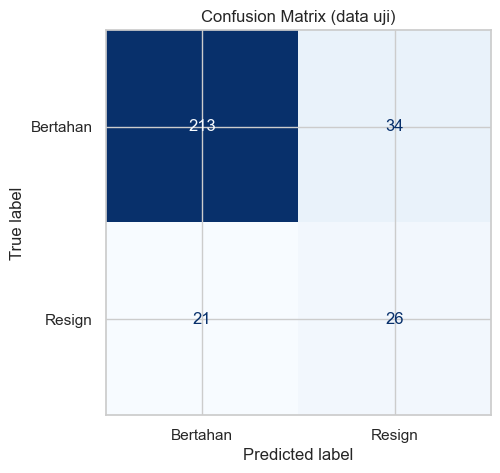

TN=213  FP=34  FN=21  TP=26


In [14]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay(cm, display_labels=["Bertahan", "Resign"]).plot(cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix (data uji)")
plt.show()

print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

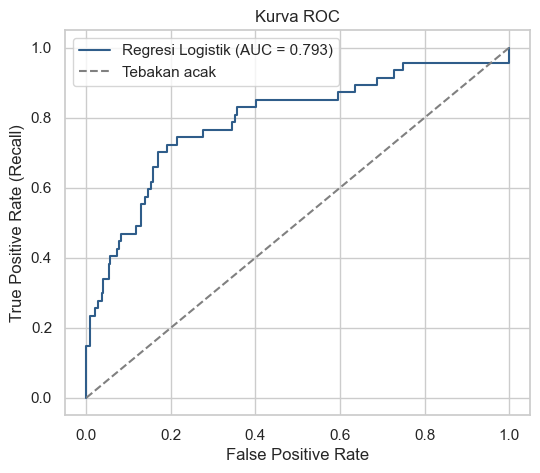

AUC: 0.7932


In [15]:
auc = roc_auc_score(y_test, y_proba)
fpr, tpr, _ = roc_curve(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#2F5D8A", label=f"Regresi Logistik (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Tebakan acak")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Kurva ROC")
plt.legend()
plt.show()
print(f"AUC: {auc:.4f}")

### 7.1 Interpretasi False Positive vs False Negative

- **False Positive (FP):** karyawan yang sebenarnya bertahan diprediksi akan resign. Akibatnya HR melakukan
  pendekatan retensi yang sebenarnya tidak perlu (biaya waktu dan sedikit biaya program).
- **False Negative (FN):** karyawan yang sebenarnya resign diprediksi bertahan. Akibatnya perusahaan kehilangan
  karyawan tanpa sempat mencegahnya, dengan biaya rekrutmen, pelatihan, dan hilangnya pengetahuan kerja.

Biasanya **FN lebih merugikan** daripada FP, sehingga **Recall kelas "Resign"** menjadi metrik utama, dengan
Precision dan F1-Score sebagai penyeimbang agar HR tidak kewalahan oleh terlalu banyak peringatan palsu.

*Tuliskan di sini angka FP dan FN dari hasilmu dan artinya dalam jumlah karyawan.*

### 7.2 Pengaruh Threshold
Menurunkan threshold membuat model lebih "waspada" (Recall naik, Precision turun).

In [16]:
baris = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (y_proba >= t).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred_t, average="binary", zero_division=0)
    _, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_t).ravel()
    baris.append({"threshold": t, "precision": p, "recall": r, "f1": f1, "FP": fp_t, "FN": fn_t})
pd.DataFrame(baris).round(3)

,threshold,precision,recall,f1,FP,FN
0,0.3,0.347,0.745,0.473,66,12
1,0.4,0.415,0.723,0.527,48,13
2,0.5,0.433,0.553,0.486,34,21
3,0.6,0.559,0.404,0.469,15,28
4,0.7,0.650,0.277,0.388,7,34


### 7.3 Perbandingan: dengan vs tanpa SMOTE
Untuk membuktikan apakah SMOTE membantu pada kasus ini.

In [17]:
model_tanpa = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model_tanpa.fit(X_train_s, y_train)

def ringkas(nama, m):
    proba = m.predict_proba(X_test_s)[:, 1]
    pred = (proba >= THRESHOLD).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average="binary", zero_division=0)
    return {"model": nama, "precision": p, "recall": r, "f1": f1, "AUC": roc_auc_score(y_test, proba)}

pd.DataFrame([ringkas("Tanpa SMOTE", model_tanpa), ringkas("Dengan SMOTE", model)]).round(3)

,model,precision,recall,f1,AUC
0,Tanpa SMOTE,0.750,0.255,0.381,0.802
1,Dengan SMOTE,0.433,0.553,0.486,0.793


## 8. Interpretasi Koefisien Model

Pada regresi logistik, `exp(koefisien)` adalah *odds ratio*. Nilai di atas 1 berarti fitur tersebut menaikkan peluang
resign; di bawah 1 berarti menurunkan. Fitur numerik sudah distandarkan, jadi perbandingannya per kenaikan 1 simpangan baku.

In [18]:
koef = pd.DataFrame({
    "fitur": X.columns,
    "koefisien": model.coef_[0],
    "odds_ratio": np.exp(model.coef_[0]),
}).sort_values("koefisien", ascending=False)

koef.round(3).reset_index(drop=True)

,fitur,koefisien,odds_ratio
0,NumCompaniesWorked,0.473,1.605
1,YearsSinceLastPromotion,0.461,1.586
2,DistanceFromHome,0.214,1.239
3,JobLevel,0.128,1.136
4,MonthlyIncome,-0.162,0.851
5,StockOptionLevel,-0.175,0.839
6,WorkLifeBalance,-0.238,0.788
7,JobSatisfaction,-0.347,0.706
8,YearsAtCompany,-0.376,0.687
9,EnvironmentSatisfaction,-0.455,0.635


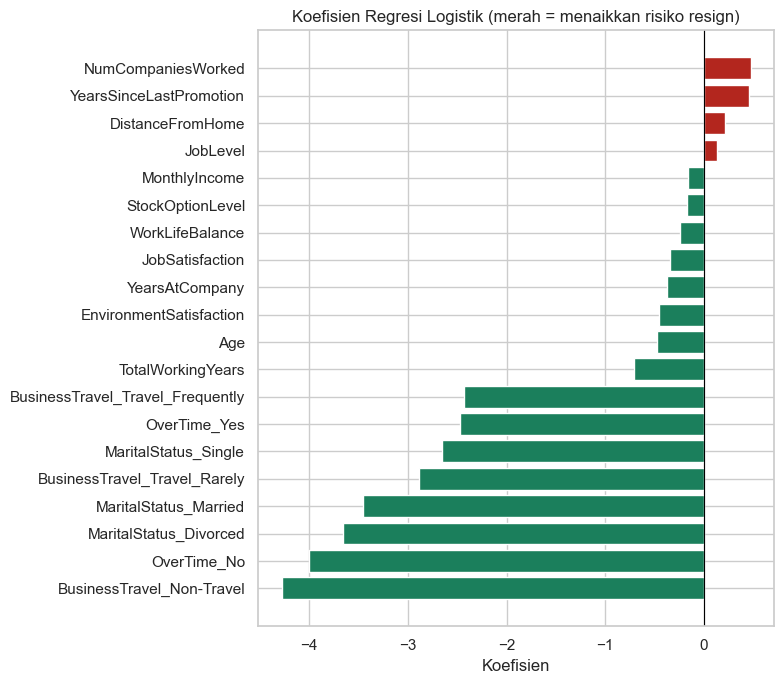

In [19]:
plt.figure(figsize=(8, 7))
warna = ["#B3261E" if v > 0 else "#1B7F5C" for v in koef["koefisien"]]
plt.barh(koef["fitur"], koef["koefisien"], color=warna)
plt.gca().invert_yaxis()
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Koefisien Regresi Logistik (merah = menaikkan risiko resign)")
plt.xlabel("Koefisien")
plt.tight_layout()
plt.show()

**Catatan:** tuliskan 3-5 faktor teratas yang menaikkan dan menurunkan risiko resign, lalu terjemahkan menjadi
rekomendasi tindakan HR (misalnya kebijakan lembur, jalur promosi, atau program kesejahteraan).

## 9. Menyimpan Model (Joblib)

Disimpan: model, scaler, dan metadata (daftar kolom fitur setelah encoding, kolom numerik, threshold, rata-rata fitur data latih, versi scikit-learn).
Aplikasi Flask memakai file-file ini.

In [20]:
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

joblib.dump(model, MODEL_DIR / "logreg_model.joblib")
joblib.dump(scaler, MODEL_DIR / "scaler.joblib")

p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="binary", zero_division=0)
metadata = {
    "feature_columns": list(X.columns),
    "numeric_cols": NUMERIC_COLS,
    "categorical_cols": CATEGORICAL_COLS,
    "threshold": THRESHOLD,
    "feature_means": {k: round(float(v), 6) for k, v in X_train_s.mean().items()},
    "sklearn_version": sklearn.__version__,
    "metrics_test": {
        "precision": round(float(p), 4),
        "recall": round(float(r), 4),
        "f1": round(float(f1), 4),
        "auc": round(float(auc), 4),
    },
}
(MODEL_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))

print("Tersimpan di folder models/")
print(f"Tambahkan ke requirements.txt:  scikit-learn=={sklearn.__version__}")

Tersimpan di folder models/
Tambahkan ke requirements.txt:  scikit-learn==1.9.1


### Uji cepat: muat ulang model dan prediksi satu karyawan

In [21]:
model_l = joblib.load(MODEL_DIR / "logreg_model.joblib")
scaler_l = joblib.load(MODEL_DIR / "scaler.joblib")
meta_l = json.loads((MODEL_DIR / "metadata.json").read_text())

contoh = pd.DataFrame([{
    "Age": 28, "MonthlyIncome": 2800, "DistanceFromHome": 20, "TotalWorkingYears": 4,
    "YearsAtCompany": 1, "YearsSinceLastPromotion": 1, "NumCompaniesWorked": 3,
    "JobLevel": 1, "StockOptionLevel": 0,
    "JobSatisfaction": 2, "EnvironmentSatisfaction": 2, "WorkLifeBalance": 2,
    "OverTime": "Yes", "MaritalStatus": "Single", "BusinessTravel": "Travel_Frequently",
}])
Xc = pd.get_dummies(contoh, columns=meta_l["categorical_cols"], dtype=int)
Xc = Xc.reindex(columns=meta_l["feature_columns"], fill_value=0)
Xc[meta_l["numeric_cols"]] = scaler_l.transform(Xc[meta_l["numeric_cols"]])

prob = model_l.predict_proba(Xc)[0, 1]
print(f"Probabilitas resign: {prob:.1%} -> {'Berisiko' if prob >= meta_l['threshold'] else 'Tidak Berisiko'}")

Probabilitas resign: 96.6% -> Berisiko


## 10. Kesimpulan dan Rekomendasi Bisnis

*Isi setelah menjalankan notebook dengan data aslimu. Poin yang perlu dibahas:*

1. Performa model (Recall, Precision, F1, AUC) dan apakah memadai.
2. Pengaruh SMOTE dan threshold terhadap Recall.
3. Faktor utama pendorong resign dan rekomendasi tindakan HR.
4. Keterbatasan: dataset fiktif IBM, jumlah data kecil, model linear, tidak ada data waktu.